# Distribution of Figure 3.3 peak-switch locations and severity

Draw **100 fresh independent standard Gaussian samples of size n=200**, independently of the earlier 1,000-sample bank. Keep Figure 3.3's bandwidth grid fixed. Start with its original coarse lambda sweep, then evaluate a finer lambda grid inside every candidate jump interval and solve for equal competing peak heights.

The fixed Figure 3.3 sample is a separate positive control; it is not counted among the 100 random samples. Every displayed figure is saved automatically as a PDF under `outputs/pdfs/spectral_lambda_switch_distribution/`.

In [1]:
from pathlib import Path
import json
import os
import sys

working_directory = Path.cwd().resolve()
code_directory = next((candidate.resolve()
    for ancestor in (working_directory, *working_directory.parents)
    for candidate in (ancestor, ancestor / "Code/Code_kde")
    if (candidate / "kde_tools/pdf_export.py").is_file()), None)
if code_directory is None:
    raise FileNotFoundError("Run this notebook from MASTERARBEIT or Code/Code_kde.")
if str(code_directory) not in sys.path:
    sys.path.insert(0, str(code_directory))
os.environ.setdefault("MPLCONFIGDIR", str(code_directory / ".matplotlib-cache"))
analysis_directory = code_directory / "outputs/analysis/spectral_lambda_switch_distribution"
if str(analysis_directory) not in sys.path:
    sys.path.insert(0, str(analysis_directory))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import switch_distribution_analysis as experiment
from kde_tools.pdf_export import enable_automatic_pdf_saving
pdf_directory = enable_automatic_pdf_saving("spectral_lambda_switch_distribution")
print("Automatic PDF exports:", pdf_directory)

Automatic PDF exports: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_switch_distribution


In [2]:
M = 100
SAMPLE_SIZE = 200
SEED = 2026101306
FINE_LAMBDA_POINTS = 201
WORKERS = 3

# Figure 3.3 grids are fixed in this experiment.
H_GRID = np.geomspace(0.01, 2.0, 201)
COARSE_LAMBDAS = np.geomspace(0.01, 1e4, 101)
print(f"{M} samples, n={SAMPLE_SIZE}; h-grid: {len(H_GRID)} points in [0.01, 2]")
print(f"Coarse lambda grid: {len(COARSE_LAMBDAS)} points in [0.01, 10000]")
print(f"Fine lambda grid: {FINE_LAMBDA_POINTS} points per candidate coarse interval")

100 samples, n=200; h-grid: 201 points in [0.01, 2]
Coarse lambda grid: 101 points in [0.01, 10000]
Fine lambda grid: 201 points per candidate coarse interval


## Coarse scan, fine scan, refined crossing

1. Draw each sample using `default_rng(SeedSequence([SEED, repetition]))`. Compute the beta=2 divergence matrix once, then select the Perron maximum at all 101 coarse lambdas.
2. Any coarse interval with a selected bandwidth-index displacement of at least two is a candidate. Evaluate **201 linearly spaced lambda values** inside that interval, keeping the h-grid unchanged. Save every fine trajectory, even when it only shows one peak moving.
3. At a fine-grid displacement, solve the difference between the largest Perron component on each side of a separating index cut. Accept a switch only if the crossing has two separated interior global maxima, an intervening valley deeper than $10^{-8}$ times the maximum component, and a resolved reversal of the peak-height order just below/above the crossing. A near-node validation interval may be widened by one neighboring fine-grid point to resolve the height order.
4. Refine a **numerical sign bracket** by bisection toward relative lambda width $10^{-6}$; save a flag if roundoff prevents that precision. Also save the root estimated by Brent's method. Neither the root solver's tolerance nor this numerical bracket is an interval-arithmetic certificate of an exact mathematical value.

Peak finding uses [SciPy `find_peaks`, prominence parameter](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.find_peaks.html). Root finding uses [SciPy `brentq`, sign-changing bracket and tolerance definitions](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.brentq.html). These grids use NumPy [geomspace](https://numpy.org/doc/stable/reference/generated/numpy.geomspace.html) and [linspace](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html). The crossing validation reuses the [earlier separated-peak detector](outputs/analysis/spectral_lambda_jump_study/repeated_peak_switch_analysis.py); the new coarse/fine workflow is in [the experiment helper](outputs/analysis/spectral_lambda_switch_distribution/switch_distribution_analysis.py).

**Declared severity measure:** for the selected bandwidths immediately below and above the crossing,

$$s=100\left(\frac{\max(h_{\rm before},h_{\rm after})}{\min(h_{\rm before},h_{\rm after})}-1\right)\%.$$

This is our descriptive, direction-independent multiplicative separation. We also save the signed change, absolute change, direction, and number of h-grid steps. No additional 20% size cutoff is imposed. For one observation per sample, the main distributions use its **largest confirmed switch by absolute log bandwidth ratio**; earliest lambda breaks a size tie. Additional switches remain in a separate table. Samples with no confirmed switch receive an explicit outcome, rather than a fabricated lambda.

In [3]:
summary = experiment.run_analysis(samples=M, sample_size=SAMPLE_SIZE, seed=SEED,
                                  fine_points=FINE_LAMBDA_POINTS, workers=WORKERS)
run_directory = Path(summary["output_directory"])
sample_results = pd.read_csv(run_directory / "sample_results.csv")
all_switches = pd.read_csv(run_directory / "all_confirmed_switches.csv")
print("Saved samples, all coarse/fine trajectories, event tables and summary:", run_directory)

Coarse-to-fine experiment: 100/100 samples cached; output /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/spectral_lambda_switch_distribution/59e74dc1d05b
{
  "output_directory": "/Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/spectral_lambda_switch_distribution/59e74dc1d05b",
  "completed_samples": 100,
  "successful_samples": 100,
  "samples_with_confirmed_switch": 29,
  "samples_without_detected_switch": 71,
  "samples_with_multiple_switches": 1,
  "confirmed_switch_events": 30,
  "upward_events": 29,
  "downward_events": 1,
  "largest_switch_per_sample_lambda": {
    "minimum": 0.5161167058656853,
    "q25": 12.812356839615985,
    "median": 30.60761052007994,
    "q75": 74.23064288010481,
    "maximum": 2165.2925337892034
  },
  "largest_switch_per_sample_severity_percent": {
    "minimum": 11.178446136245345,
    "q25": 79.10730514396744,
    "median": 121.38821534568862,
    "q75": 152.74364777307105,
    "maximum": 276.0603093086395
  },
  "largest_swit

In [4]:
counts = pd.DataFrame({"outcome": ["confirmed switch", "no detected switch", "numerical failure", "multiple switches"],
                      "samples": [summary["samples_with_confirmed_switch"],
                                  summary["samples_without_detected_switch"],
                                  summary["completed_samples"]-summary["successful_samples"],
                                  summary["samples_with_multiple_switches"]]})
display(counts)
stats = pd.DataFrame({
    "refined crossing lambda": summary["largest_switch_per_sample_lambda"],
    "bandwidth separation (%)": summary["largest_switch_per_sample_severity_percent"],
    "absolute bandwidth change": summary["largest_switch_per_sample_absolute_delta_h"]})
display(stats)
print("All events:", summary["confirmed_switch_events"],
      "upward:", summary["upward_events"], "downward:", summary["downward_events"])
print("Maximum numerical bracket width (relative):", summary["maximum_refined_relative_bracket_width"])
print("Roundoff-limited brackets:", summary["roundoff_limited_brackets"])
columns = ["repetition", "coarse_lambda_left", "coarse_lambda_right", "fine_grid_lambda_left",
           "fine_grid_lambda_right", "lambda_crossing", "refined_lambda_left", "refined_lambda_right",
           "h_before", "h_after", "severity_percent", "direction"]
display(sample_results.loc[sample_results["status"] == "confirmed_switch", columns].sort_values("lambda_crossing"))

All events: 30 upward: 29 downward: 1
Maximum numerical bracket width (relative): 7.136269106107386e-07
Roundoff-limited brackets: 0


,outcome,samples
0,confirmed switch,29
1,no detected switch,71
2,numerical failure,0
3,multiple switches,1


,refined crossing lambda,bandwidth separation (%),absolute bandwidth change
minimum,0.516117,11.178446,0.025468
q25,12.812357,79.107305,0.084664
median,30.607611,121.388215,0.120605
q75,74.230643,152.743648,0.181588
maximum,2165.292534,276.060309,0.307590


,repetition,coarse_lambda_left,coarse_lambda_right,fine_grid_lambda_left,fine_grid_lambda_right,lambda_crossing,refined_lambda_left,refined_lambda_right,h_before,h_after,severity_percent,direction
33,33,0.478630,0.549541,0.515858,0.516213,0.516117,0.516117,0.516117,0.071020,0.157230,121.388215,upward
68,68,2.187762,2.511886,2.447061,2.448682,2.448345,2.448345,2.448346,0.092562,0.145218,56.887214,upward
32,32,4.365158,5.011872,4.659413,4.662647,4.662557,4.662555,4.662558,0.078959,0.174806,121.388215,upward
52,52,4.365158,5.011872,4.740252,4.743486,4.740401,4.740401,4.740404,0.063879,0.145218,127.331517,upward
63,63,7.585776,8.709636,8.125229,8.130848,8.130002,8.129997,8.130003,0.078959,0.199564,152.743648,upward
96,96,7.585776,8.709636,8.243234,8.248853,8.247062,8.247058,8.247064,0.076895,0.204921,166.495911,upward
20,20,10.000000,11.481536,10.525945,10.533353,10.528617,10.528614,10.528621,0.090142,0.174806,93.922745,upward
93,93,11.481536,13.182567,12.808341,12.816846,12.812357,12.812352,12.812360,0.097598,0.165785,69.864646,upward
71,71,13.182567,15.135612,14.823125,14.832890,14.828834,14.828827,14.828837,0.081079,0.274248,238.249294,upward
44,44,15.135612,17.378008,15.774695,15.785907,15.782090,15.782085,15.782096,0.085490,0.267078,212.407498,upward


## Distribution of where the largest confirmed switch occurs and how large it is

The first panel assigns the **same confirmed switches** to the original coarse lambda intervals. The second shows their refined crossing lambdas; the third shows bandwidth separation, and the fourth relates crossing location to severity. Every panel uses one largest confirmed event per switch sample. The sample count with no detected switch is displayed separately in the title and outcome table, so these histograms are conditional on detection.

A finer lambda grid improves location within a candidate interval; it does not refine the bandwidth domain or change the 201-node h-grid. A short switch followed by a switch back within one coarse interval can be missed if the interval's endpoint selections do not produce a candidate. “No detected switch” therefore refers to this stated search, rather than an exhaustive theorem for all continuous lambda.

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_switch_distribution/001_100_independent_samples_switch_locations_and_severity_29_samples_with_a_confirme.pdf
Saved distribution figure: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/images/spectral_lambda_switch_distribution/59e74dc1d05b/switch_location_and_severity_distributions.png


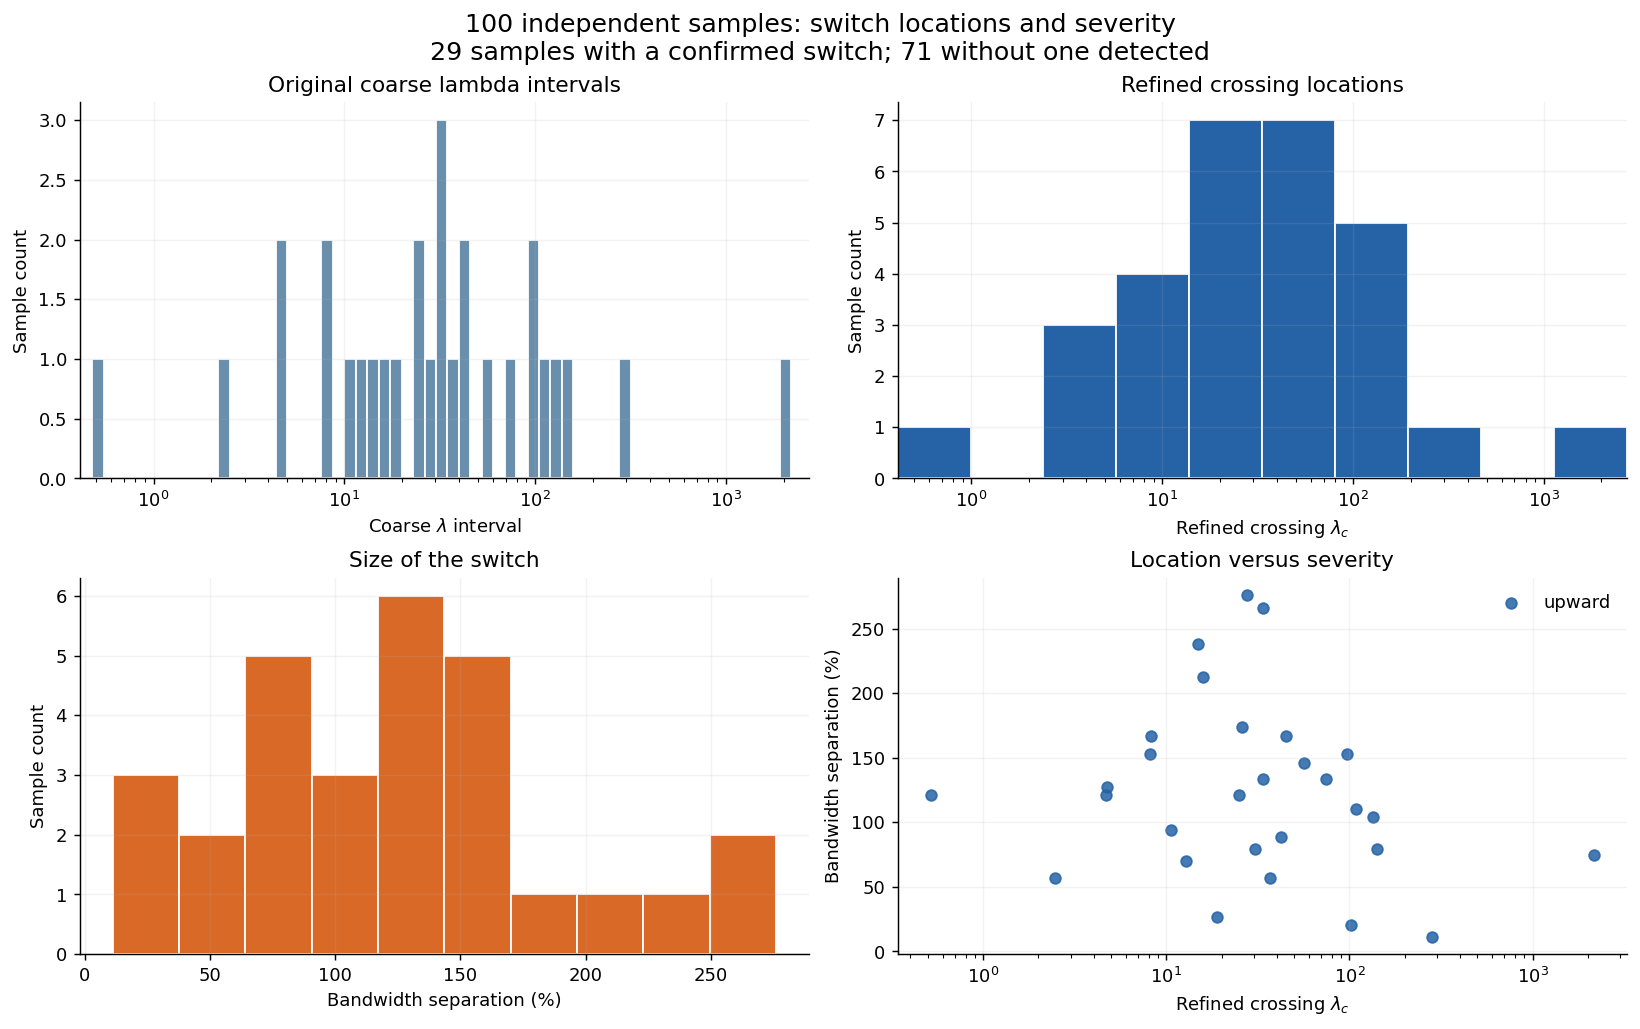

In [5]:
distribution_image = experiment.plot_distributions(summary)
print("Saved distribution figure:", distribution_image)

## Verify the refinement on Figure 3.3 and one independent sample

The first row uses the original Figure 3.3 sample (seed 20260823, n=200). The second uses a random-sample crossing selected deterministically from the middle of the observed lambda ordering. The plots show the coarse candidate interval, the fine selected-bandwidth trajectory, and the sign-changing peak-height difference. Connecting lines guide the eye between evaluated lambda values.

The Figure 3.3 reference must reproduce the original finite-h-grid crossing near $17.8737506447$. Its numerical value differs from the earlier off-node/midpoint-grid limit estimate because this experiment deliberately retains Figure 3.3's original h-grid. An independent dense eigensolver is checked immediately below/above the reference crossing and five random-sample crossings spanning the observed lambda ordering.

In [6]:
control = json.loads((run_directory / "figure_3_3_control.json").read_text())
control_event = experiment.representative_event(control["events"])
display(pd.DataFrame([{key: control_event[key] for key in [
    "coarse_lambda_left", "coarse_lambda_right", "fine_grid_lambda_left", "fine_grid_lambda_right",
    "lambda_crossing", "refined_lambda_left", "refined_lambda_right", "h_before", "h_after", "severity_percent"]}]))
validation = experiment.validate_independent_eigensolver(summary)
print("Independent solver checks:", len(validation["checks"]))
print("Maximum vector component discrepancy:", validation["maximum_vector_component_discrepancy"])

Independent solver checks: 12
Maximum vector component discrepancy: 3.642919299551295e-17


,coarse_lambda_left,coarse_lambda_right,fine_grid_lambda_left,fine_grid_lambda_right,lambda_crossing,refined_lambda_left,refined_lambda_right,h_before,h_after,severity_percent
0,17.378008,19.952623,17.867185,17.880058,17.873751,17.873746,17.873759,0.111421,0.204921,83.91555


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_switch_distribution/001_locate_a_switch_coarse_scan_fine_grid_equal_peak_heights.pdf
Saved coarse-to-fine examples: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/images/spectral_lambda_switch_distribution/59e74dc1d05b/coarse_to_fine_switch_examples.png


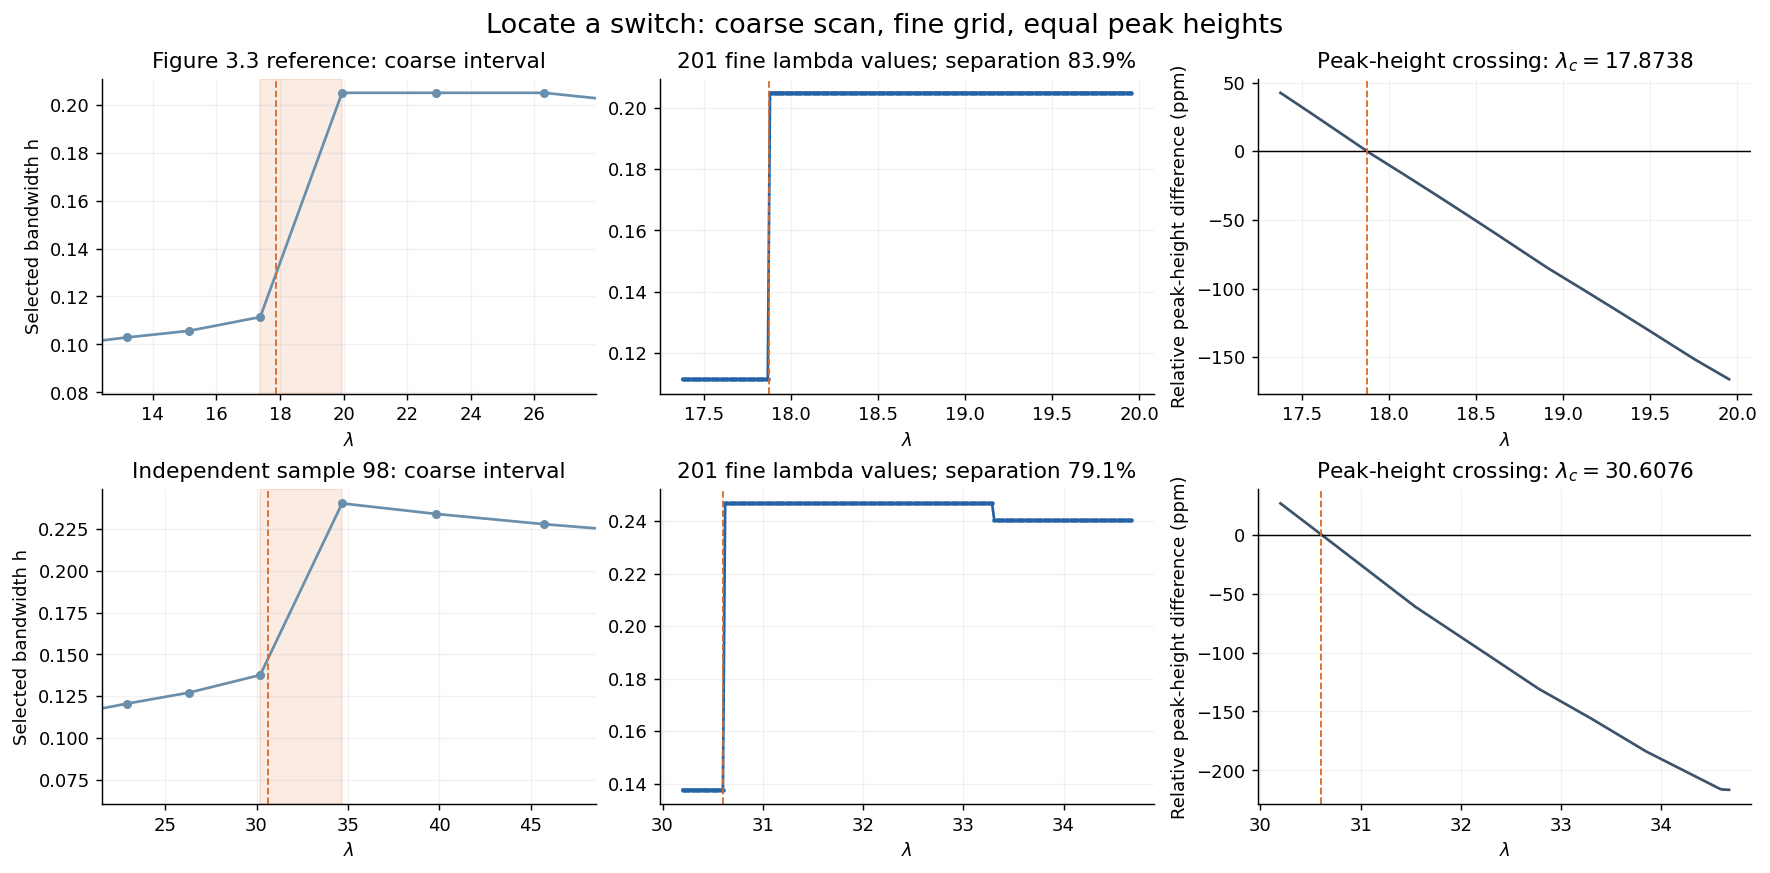

In [7]:
refinement_image = experiment.plot_refinement_examples(summary)
print("Saved coarse-to-fine examples:", refinement_image)

## Saved outputs and scope

- `sample_results.csv`: one row per sample, explicit detection outcome, largest confirmed event, coarse/fine/narrow lambda brackets, and severity measures.
- `all_confirmed_switches.csv`: every confirmed event, including additional switches in a sample.
- `checkpoint.json`: resumable results, full coarse trajectories, all fine trajectories and rejected fine candidates.
- `samples_and_grids.npz`: the actual samples and unchanged h/coarse-lambda grids.
- `figure_3_3_control.json`, `validation.json`, `summary.json`: reference reconstruction, independent eigensolver checks, and summary statistics.

All locations and frequencies remain conditional on the standard Gaussian sample model, n=200, this h-grid, the lambda search domain and the declared peak-resolution filter. Changing M, n, the seed or the fine-grid point count produces a separate output directory. The protected thesis files are not modified by this experiment.

## Ten Figure 3.3-type paths

Show selected bandwidth versus lambda for **ten archived independent samples**, with the original coarse evaluations and local fine scans combined. All panels use the same lambda range and a common linear bandwidth axis. Orange dashed lines and segments mark the confirmed peak switches. Horizontal red dotted lines and a faint band mark each sample's closest adjacent bandwidth pair from Section 3.5.1; both pair values appear above its panel. These lines are horizontal because h is on the vertical axis. Connecting lines between evaluated values guide the eye.

The selection is illustrative: seven switching samples spanning the ranks of largest-switch lambda (including the multiple-switch example), plus three samples with no detected switch spanning final-bandwidth ranks. It is deliberately not a random or proportionally sampled subset, so these ten panels do not estimate the overall switching frequency. The 29/100 frequency and its stated numerical-detection scope come from the complete experiment above. Sample labels are zero-based repetition indices in the saved tables.

`ten_example_paths_with_closest_pair.json` saves the exact selected sample indices, detected crossings, severity values, closest bandwidth pairs and selection rule. The figures use the same [cached trajectories](outputs/data/spectral_lambda_switch_distribution/59e74dc1d05b/checkpoint.json) and [plotting helper](outputs/analysis/spectral_lambda_switch_distribution/switch_distribution_analysis.py) as the rest of this notebook.


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_switch_distribution/001_ten_figure_3_3_type_sample_paths_examples_1_6_with_closest_pairs.pdf
Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/spectral_lambda_switch_distribution/002_ten_figure_3_3_type_sample_paths_examples_7_10_with_closest_pairs.pdf
Saved Figure 3.3-type sample paths with closest pairs: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/images/spectral_lambda_switch_distribution/59e74dc1d05b/ten_figure_3_3_type_paths_1_with_closest_pair.png
Saved Figure 3.3-type sample paths with closest pairs: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/images/spectral_lambda_switch_distribution/59e74dc1d05b/ten_figure_3_3_type_paths_2_with_closest_pair.png


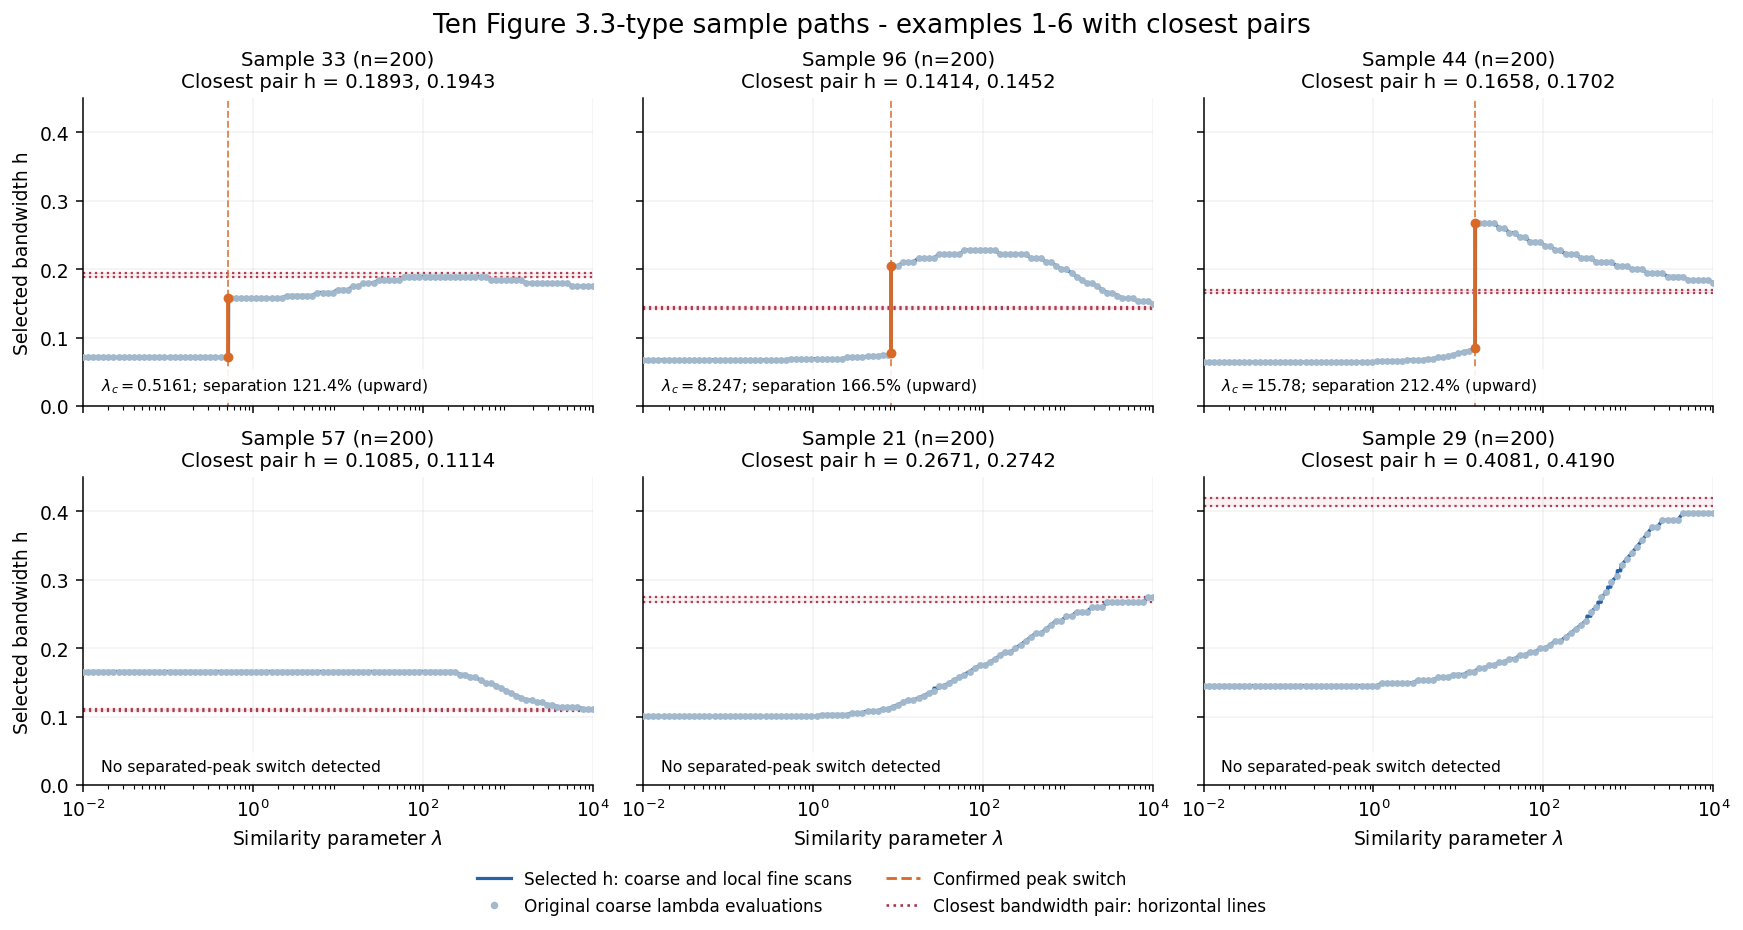

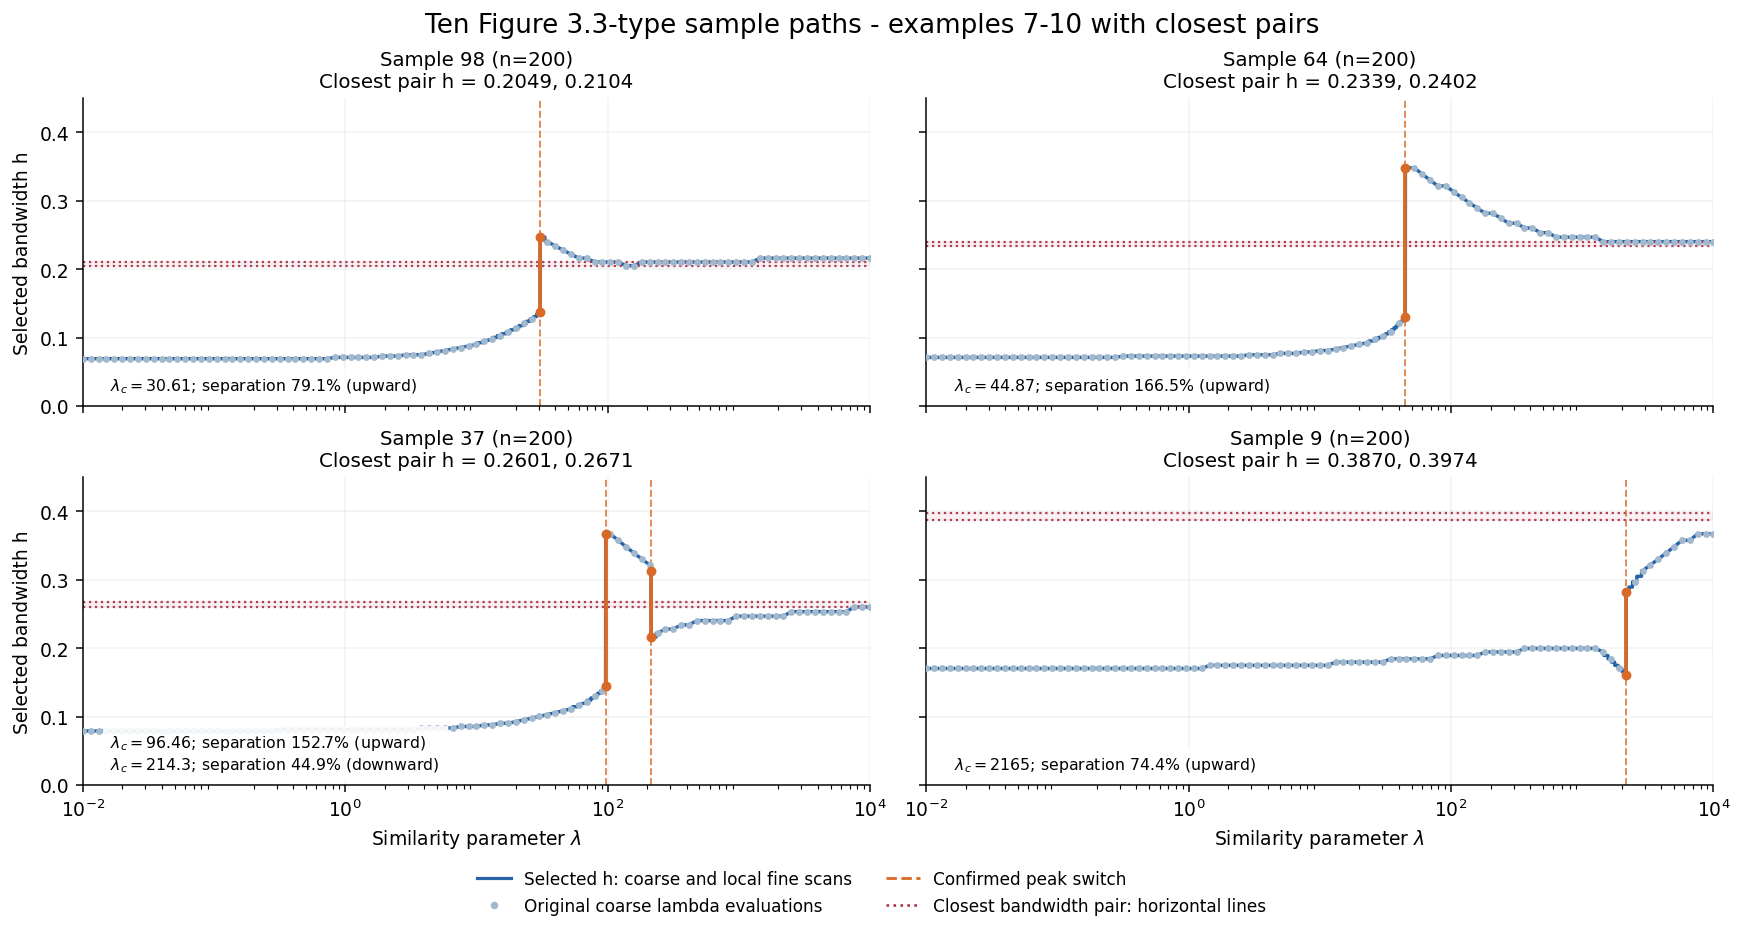

In [10]:
ten_example_images = experiment.plot_ten_paths(summary, include_closest_pair=True)
for image_path in ten_example_images:
    print("Saved Figure 3.3-type sample paths with closest pairs:", image_path)


## Check the fixed-grid limit from Section 3.5.1

The protected thesis's [Section 3.5.1, “Convergence to closest adjacent pair”](../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex) concerns **fixed N and lambda tending to infinity**. For a sample X, if the global off-diagonal minimum of its divergence matrix is attained by a unique adjacent pair $(j,j+1)$, the predicted sum-normalized Perron limit is

$$v_X(\lambda)\longrightarrow\tfrac12 e_j+\tfrac12 e_{j+1}.$$

The limit is sample specific: it is not a common bandwidth shared by all repeated samples. The two limiting components are equal. The shared solver's [near-tie convention](kde_tools/perron.py) selects the lower grid index once their difference is at roundoff level; the vector-limit statement itself identifies the pair.

The [check helper](outputs/analysis/spectral_lambda_switch_distribution/check_closest_pair_limit.py) checks every saved sample's global closest pair, tests whether it is unique and adjacent, and compares its Perron vector with the predicted limit. **Our bound on the computed matrix:** with $\delta$ the difference between the second-smallest and smallest upper-triangle divergence entries,

$$\|\widetilde A(\lambda)-B\|_{\rm op}\le (N-1)e^{-\lambda\delta}.$$

This follows by bounding each remaining edge and then the maximum absolute row sum of the symmetric remainder. The limiting single-edge matrix B has largest eigenvalue 1, which is simple and separated from the next eigenvalue 0. [Yu, Wang and Samworth, Theorem 2, pp. 3-4](https://arxiv.org/pdf/1405.0680) supplies the symmetric eigenvector perturbation bound needed to turn matrix convergence into eigenvector convergence. We choose a separate terminal lambda for each sample so the displayed remainder bound is at most $10^{-10}$ and verify the vector numerically.

All 100 computed matrices have unique adjacent closest pairs and agree with the predicted vector at the terminal test points (largest L1 discrepancy below $9.1\times10^{-13}$). **These terminal lambdas are conservative test points, not estimates of the earliest convergence time.** This is a check on the computed divergence matrices, not interval-certified exact integration.

At lambda $10^4$, only 42/100 samples and 4/10 displayed examples select one of the limiting pair's nodes. Choosing a pair member does not establish full vector concentration: the saved endpoint vectors still spread their mass over other nodes. Thus the displayed finite-lambda paths, including their plateaus and switches, should not all be read as having already reached the limit. A path with no detected separated-peak switch or a path with multiple switches can still have this same eventual closest-pair mechanism. This is distinct from the joint N/lambda limit discussed in the next subsection.


In [9]:
import check_closest_pair_limit as closest_pair_check
closest_pair_directory = run_directory / "closest_pair_limit"
closest_pair_summary_path = closest_pair_directory / "summary.json"
closest_pair_summary = (json.loads(closest_pair_summary_path.read_text())
                       if closest_pair_summary_path.is_file()
                       else closest_pair_check.run_checks(run_directory))
print("Unique adjacent closest pairs:", closest_pair_summary["unique_closest_pairs"],
      "of", closest_pair_summary["samples"])
print("Maximum terminal vector L1 discrepancy:", closest_pair_summary["maximum_terminal_l1_vector_error"])
print("Displayed samples selecting a closest-pair node at lambda=10000:",
      closest_pair_summary["ten_examples_selected_at_10000_in_pair"], "of 10")
closest_pair_examples = pd.read_csv(closest_pair_directory / "ten_example_results.csv")
display(closest_pair_examples[["repetition", "h_selected_at_10000", "lower_pair_h", "upper_pair_h",
                              "selected_at_10000_in_pair", "terminal_l1_vector_error"]])


Unique adjacent closest pairs: 100 of 100
Maximum terminal vector L1 discrepancy: 9.000682224042828e-13
Displayed samples selecting a closest-pair node at lambda=10000: 4 of 10


,repetition,h_selected_at_10000,lower_pair_h,upper_pair_h,selected_at_10000_in_pair,terminal_l1_vector_error
0,33,0.174806,0.189266,0.194347,False,5.045827e-13
1,96,0.149116,0.141421,0.145218,False,5.100949e-13
2,44,0.179499,0.165785,0.170236,False,4.996001e-13
3,57,0.111421,0.108508,0.111421,True,4.999112e-13
4,21,0.274248,0.267078,0.274248,True,5.002525e-13
5,29,0.397389,0.408057,0.419012,False,4.999112e-13
6,98,0.216071,0.204921,0.210423,False,4.999473e-13
7,64,0.240225,0.233945,0.240225,True,5.001904e-13
8,37,0.260096,0.260096,0.267078,True,5.001705e-13
9,9,0.367029,0.387000,0.397389,False,4.999112e-13
